# Copula Pairs Trading Implementation

Sources are from Sabino da Silva, Ziegelmann & Caldeira (2017), Mixed Copula Pairs Trading Strategy on the S&P 500.

**Pairs:**
| Pair | Tickers | Venue |
|---|---|---|
| Apple / Alphabet | `AAPL`, `GOOGL` | NASDAQ | 
| LVMH / Hermès | `MC.PA`, `RMS.PA` | Euronext Paris | 

The paper uses daily S&P 500 data and a large universe from which it selects pairs. We fix our own pairs and move the strategy to hourly bars.
 
This notebook covers the methodology, the data import, the marginals and copula fitting, the signals, and a backtest whose P&L follows Rad, Low & Faff (2016), *The profitability of pairs trading strategies: distance, cointegration and copula methods*, Quantitative Finance.

## 1. The strategy in the paper

We shall briefly recall the paper's mathematical tools.

### 1.1 Copula decomposition
The joint distribution of the returns $(R^X, R^Y)$ factorises as
$$H(r^X, r^Y) = C\big(F_X(r^X),\, F_Y(r^Y)\big),$$
which separates the marginals $F_X, F_Y$ from the dependence structure $C$, the copula. Both can be modelled independently.

### 1.2 Mispricing indices
The partial derivatives of the copula are conditional CDFs:
$$MI^{X|Y}_t = \frac{\partial C(u_1,u_2)}{\partial u_2} = P\big(U_1 \le u_1 \mid U_2 = u_2\big), \qquad MI^{Y|X}_t = \frac{\partial C(u_1,u_2)}{\partial u_1},$$
with $u_1 = F_X(r^X_t)$, $u_2 = F_Y(r^Y_t)$. A value of $0.5$ means that $X$ is fairly priced relative to $Y$ on that bar.

These are accumulated over the trading window, $t$:
$$m_{1,t} = MI^{X|Y}_t - 0.5,\quad m_{2,t} = MI^{Y|X}_t - 0.5,\qquad M_{i,t} = M_{i,t-1} + m_{i,t},\quad M_{i,0}=0.$$

### 1.3 Pipeline 
1. We fit $GARCH(1,1)$ to each return series and extract the standardised residuals $\hat\varepsilon_t = (x_t-\hat\mu_t)/\hat\sigma_t$, this will filter out each stock's own volatility.
2. Get the observations $u_t = \frac{T}{T+1}\hat F(\hat\varepsilon_t)$, using the empirical CDF.
3. Copula fitting with Gaussian, Student-$t$, Clayton, Frank, Gumbel, and two mixtures, then keep the best by log-likelihood:
$$C^{CFG} = \pi_1 C^{Clayton}_\alpha + \pi_2 C^{Frank}_\beta + (1-\pi_1-\pi_2)\, C^{Gumbel}_\delta,$$
$$C^{CtG} = \pi_1 C^{Clayton}_\alpha + \pi_2 C^{t}_{\rho,\nu} + (1-\pi_1-\pi_2)\, C^{Gumbel}_\delta.$$
   Clayton captures lower-tail dependence and Gumbel upper-tail dependence; Frank and $t$ cover the symmetric middle. In the paper, CtG wins about 65% of the time.

4. Filter new returns with the GARCH parameters, map them through the formation-period ECDF, compute $MI$, and accumulate $M_{1,t}, M_{2,t}$.

### 1.4 Trading rules ($\Delta_1 = 0.2,\ \Delta_2=-0.2,\ \Delta_3=\Delta_4=0$)
- If $M_{1,t} > 0.2$ and $M_{2,t} < -0.2$, then $X$ is overvalued: short $X$, long $Y$.
- If $M_{1,t} < -0.2$ and $M_{2,t} > 0.2$, then long $X$, short $Y$.
- Exit when the indices revert or at the end of the trading window.
- Costs: each leg traded pays a one-way cost, so a complete pair trade (open + close, two legs each) pays 4 × that cost. The default is 20 bp per complete pair trade; see §13.

## 2. Adapting the strategy to hourly bars

| Paper (daily) | This notebook (1h) | Rationale |
|---|---|---|
| Formation: 12 months (~252 obs) | ~3 months (~400–550 bars) | Gives a comparable sample size for the GARCH and copula fits |
| Trading: 6 months | ~1 month | Keeps the 2:1 to 4:1 formation-to-trading ratio and refits more often |
| Close-to-close returns | Hourly log returns | The **overnight gap** bar is far more volatile than intraday bars and is handled explicitly (see below) |
| Universe-selected pairs | Fixed pairs | Pairs are chosen ex ante |
| 20 bp round-trip | 20 bp per complete pair trade (tested 0–58 bp) | Intraday turnover is higher, so costs dominate |

**Points to handle carefully:**
- **Overnight / weekend gaps.** The first bar of each session contains the overnight return. Options:
  - (a) Drop it (pure intraday).
  - (b) Keep it with a dummy in the GARCH mean or variance.
  - (c) Rescale it by its own volatility.
  
  We use (a) for the GARCH and copula fit. In the backtest, positions are still held through the overnight bar, so its P&L is included.
- **Intraday seasonality.** Volatility is U-shaped across the session. We deseasonalise returns by dividing by the time-of-day average absolute return *before* the GARCH step, so that GARCH captures only the persistent component.
- **Synchronicity.** Each pair trades on a single venue, so bars align exactly. US and Paris data are never mixed within a pair.
- **Yahoo limitation.** For `interval="60m"`, Yahoo serves only the last **730 calendar days**. This gives about 2 years of data, i.e. about 20 rolling formation/trading cycles at a 3m/1m split. For longer histories, you can either append to a local store over time or use a paid source (Polygon, Databento, IBKR).
- **Bar timestamps.** Yahoo's hourly bars for US stocks are stamped at :30 (09:30, 10:30, …, 15:30). The last bar is a 30-minute bar. Paris bars start at 09:00, and the last bar is 17:00–17:30.

## 3. Setup

In [1]:
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)

PAIRS = {
    "AAPL_GOOGL": {"tickers": ("AAPL", "GOOGL"),   "tz": "America/New_York"},
    "MC_RMS":     {"tickers": ("MC.PA", "RMS.PA"), "tz": "Europe/Paris"},
}
TICKERS = sorted({t for p in PAIRS.values() for t in p["tickers"]})
INTERVAL = "60m"
LOOKBACK_DAYS = 729   # Yahoo hard cap for intraday 60m is 730 days

## 4. Download 1h candles from Yahoo
`period="730d"` sometimes returns an error at the boundary, so we request explicit `start`/`end` dates. We download each ticker separately, which makes failures easy to see and retry, and we cache to parquet to avoid re-downloading.

In [2]:
def fetch_hourly(ticker: str, lookback_days: int = LOOKBACK_DAYS, retries: int = 3) -> pd.DataFrame:
    end = pd.Timestamp.utcnow().normalize() + pd.Timedelta(days=1)
    start = end - pd.Timedelta(days=lookback_days)
    for k in range(retries):
        try:
            df = yf.download(ticker, start=start.strftime("%Y-%m-%d"), end=end.strftime("%Y-%m-%d"),
                             interval=INTERVAL, auto_adjust=True, prepost=False,
                             progress=False, threads=False)
            if not df.empty:
                break
        except Exception as e:
            print(f"{ticker}: attempt {k+1} failed ({e})")
        time.sleep(2 * (k + 1))
    else:
        raise RuntimeError(f"No data for {ticker}")
    if isinstance(df.columns, pd.MultiIndex):          # yfinance >= 0.2.40 returns (field, ticker)
        df.columns = df.columns.get_level_values(0)
    df = df[["Open", "High", "Low", "Close", "Volume"]].copy()
    df.index = pd.DatetimeIndex(df.index).tz_convert("UTC")
    df.index.name = "ts_utc"
    return df[~df.index.duplicated(keep="last")].sort_index()


def load_or_fetch(ticker: str, refresh: bool = False) -> pd.DataFrame:
    path = DATA_DIR / f"{ticker.replace('.', '_')}_1h.parquet"
    if path.exists() and not refresh:
        cached = pd.read_parquet(path)
        new = fetch_hourly(ticker, lookback_days=30)    # top up recent bars, keep older history
        df = pd.concat([cached, new]); df = df[~df.index.duplicated(keep="last")].sort_index()
    else:
        df = fetch_hourly(ticker)
    df.to_parquet(path)
    return df


raw = {t: load_or_fetch(t) for t in TICKERS}
for t, df in raw.items():
    print(f"{t:7s} {len(df):5d} bars  {df.index[0]}  ->  {df.index[-1]}")

AAPL     3478 bars  2024-10-08 13:30:00+00:00  ->  2026-10-07 19:30:00+00:00
GOOGL    3478 bars  2024-10-08 13:30:00+00:00  ->  2026-10-07 19:30:00+00:00
MC.PA    4566 bars  2024-10-08 07:00:00+00:00  ->  2026-10-07 15:00:00+00:00
RMS.PA   4565 bars  2024-10-08 07:00:00+00:00  ->  2026-10-07 15:00:00+00:00


## 5. Clean and align each pair (local session time)

In [3]:
def build_pair(pair: str) -> pd.DataFrame:
    tx, ty = PAIRS[pair]["tickers"]; tz = PAIRS[pair]["tz"]
    px = pd.concat({tx: raw[tx]["Close"], ty: raw[ty]["Close"]}, axis=1).dropna()   # inner join on common bars
    px.index = px.index.tz_convert(tz)
    px = px[px.index.dayofweek < 5]
    # keep only days where both legs have a full session (drops half-days / partial outages)
    n_per_day = px.groupby(px.index.date).size()
    full = n_per_day[n_per_day >= n_per_day.mode().iloc[0]].index
    px = px[np.isin(px.index.date, full)]
    return px

prices = {p: build_pair(p) for p in PAIRS}
for p, px in prices.items():
    bpd = px.groupby(px.index.date).size().mode().iloc[0]
    print(f"{p:11s} {len(px):5d} bars | {px.index.normalize().nunique()} days | {bpd} bars/day | "
          f"bar times: {sorted(set(px.index.strftime('%H:%M')))}")

AAPL_GOOGL   3458 bars | 494 days | 7 bars/day | bar times: ['09:30', '10:30', '11:30', '12:30', '13:30', '14:30', '15:30']
MC_RMS       4518 bars | 502 days | 9 bars/day | bar times: ['09:00', '10:00', '11:00', '12:00', '13:00', '14:00', '15:00', '16:00', '17:00']


## 6. Returns, with the overnight bar flagged
`is_open` marks the first bar of each session. That bar's return includes the overnight gap, so it is excluded from the copula fit

In [4]:
def build_returns(px: pd.DataFrame) -> pd.DataFrame:
    r = np.log(px).diff()
    day = pd.Series(px.index.date, index=px.index)
    r["is_open"] = day.ne(day.shift())
    return r.dropna()

rets = {p: build_returns(px) for p, px in prices.items()}
for p, r in rets.items():
    cols = list(PAIRS[p]["tickers"])
    intr, ovn = r.loc[~r.is_open, cols], r.loc[r.is_open, cols]
    print(f"\n{p}")
    print(pd.DataFrame({"intraday std (bp)": intr.std() * 1e4, "overnight std (bp)": ovn.std() * 1e4,
                        "corr intraday": intr.corr().iloc[0, 1], "corr overnight": ovn.corr().iloc[0, 1]}).round(2))


AAPL_GOOGL
       intraday std (bp)  overnight std (bp)  corr intraday  corr overnight
AAPL               43.82              142.42           0.41            0.27
GOOGL              48.69              171.12           0.41            0.27

MC_RMS
        intraday std (bp)  overnight std (bp)  corr intraday  corr overnight
MC.PA               46.36              162.76           0.73            0.72
RMS.PA              48.21              154.69           0.73            0.72


## 7. Normalised prices and spread

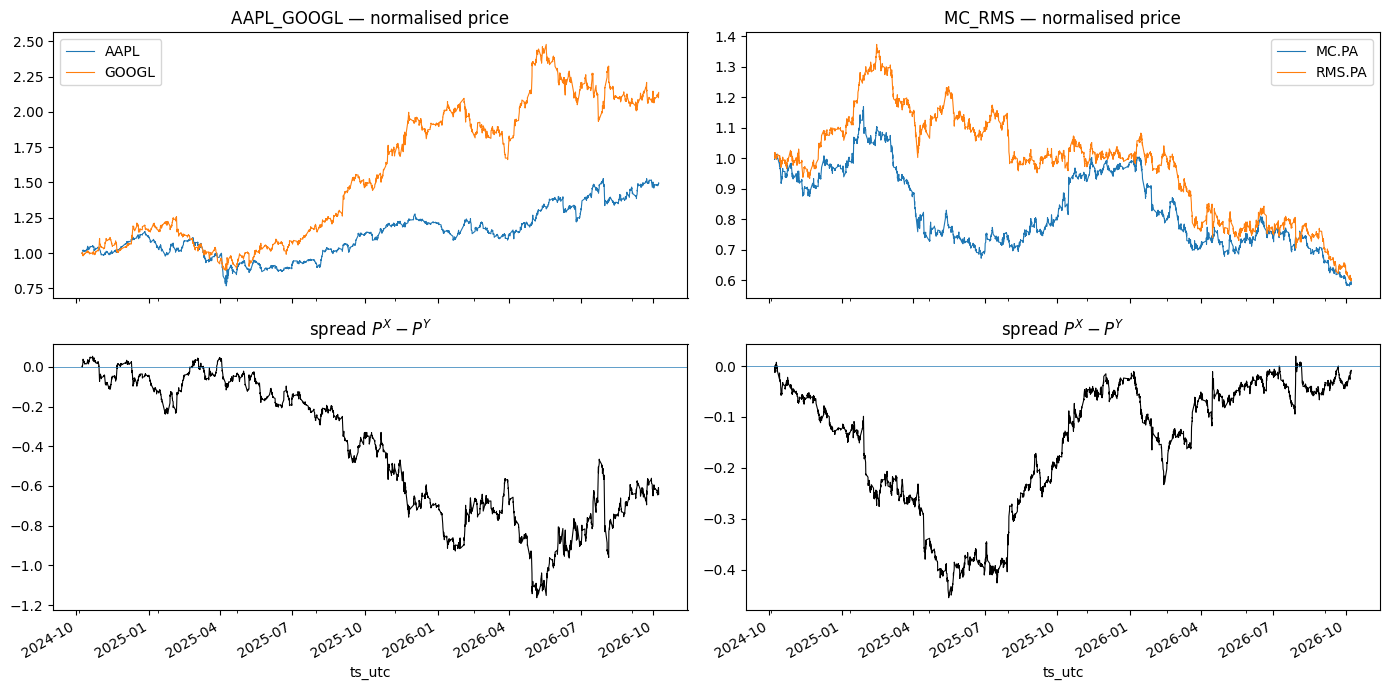

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex="col")
for j, (p, px) in enumerate(prices.items()):
    norm = px / px.iloc[0]
    norm.plot(ax=axes[0, j], lw=0.8); axes[0, j].set_title(f"{p} — normalised price")
    (norm.iloc[:, 0] - norm.iloc[:, 1]).plot(ax=axes[1, j], lw=0.8, color="k")
    axes[1, j].axhline(0, lw=0.5); axes[1, j].set_title("spread $P^X - P^Y$")
plt.tight_layout(); plt.show()

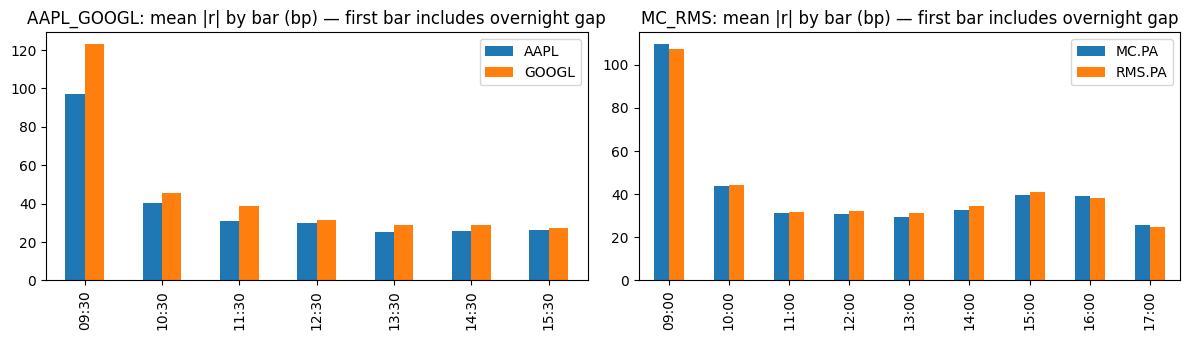

In [6]:
# Intraday volatility profile (U-shape) -> motivates deseasonalisation before GARCH
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, (p, r) in zip(axes, rets.items()):
    cols = list(PAIRS[p]["tickers"])
    r[cols].abs().groupby(r.index.strftime("%H:%M")).mean().mul(1e4).plot.bar(ax=ax)
    ax.set_title(f"{p}: mean |r| by bar (bp) — first bar includes overnight gap"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 8. Save the clean data and plan the rolling windows

In [7]:
for p in PAIRS:
    prices[p].to_parquet(DATA_DIR / f"{p}_prices_1h.parquet")
    rets[p].to_parquet(DATA_DIR / f"{p}_returns_1h.parquet")

FORMATION_DAYS, TRADING_DAYS = 63, 21     # ~3m / ~1m, rolled forward by TRADING_DAYS

def rolling_windows(idx: pd.DatetimeIndex, f=FORMATION_DAYS, t=TRADING_DAYS):
    days = pd.Index(sorted(set(idx.date)))
    out, s = [], 0
    while s + f + t <= len(days):
        out.append((days[s], days[s + f - 1], days[s + f], days[s + f + t - 1])); s += t
    return pd.DataFrame(out, columns=["form_start", "form_end", "trade_start", "trade_end"])

for p in PAIRS:
    w = rolling_windows(prices[p].index)
    print(f"{p}: {len(w)} formation/trading cycles"); display(w.head(3))

AAPL_GOOGL: 20 formation/trading cycles


,form_start,form_end,trade_start,trade_end
0,2024-10-08,2025-01-10,2025-01-13,2025-02-11
1,2024-11-06,2025-02-11,2025-02-12,2025-03-13
2,2024-12-09,2025-03-13,2025-03-14,2025-04-11


MC_RMS: 20 formation/trading cycles


,form_start,form_end,trade_start,trade_end
0,2024-10-08,2025-01-09,2025-01-10,2025-02-07
1,2024-11-06,2025-02-07,2025-02-10,2025-03-10
2,2024-12-05,2025-03-10,2025-03-11,2025-04-08


## 9. GARCH(1,1) marginals

For each stock and each formation window we fit a constant-mean GARCH(1,1)


We set $\tilde r_t = r_t / s(h_t)$, where $s(h)$ is the mean $|r|$ of bar-of-day $h$ over the formation window, normalised to mean 1 so that GARCH only models persistent volatility.

Fit with Student-$t$ innovations to $\tilde r_t$ on the formation window only. 
$$\tilde r_t = \mu + \sigma_t \varepsilon_t,\qquad \sigma_t^2 = \omega + \alpha(\tilde r_{t-1}-\mu)^2 + \beta\sigma_{t-1}^2 .$$

Run the variance recursion over formation + trading with the frozen parameters. Because $\sigma_t$ only uses information up to $t-1$, this is look-ahead free. The standardised residuals are $\hat\varepsilon_t = (\tilde r_t - \hat\mu)/\hat\sigma_t$.

Finally set $u_t = \frac{T}{T+1}\hat F_{\text{form}}(\hat\varepsilon_t)$, using the formation-window ECDF for both windows. Out-of-sample extremes are clipped inside $(0,1)$.

The overnight bar (`is_open`) is dropped and the GARCH recursion runs on intraday bars only.

In [8]:
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox

def seasonal_factor(r: pd.Series) -> pd.Series:
    """Mean |r| per bar-of-day over the formation window, normalised to mean 1."""
    s = r.abs().groupby(r.index.strftime("%H:%M")).mean()
    return s / s.mean()


def fit_marginal(r_form: pd.Series, r_trade: pd.Series) -> dict:
    """Deseasonalise -> GARCH(1,1)-t on formation -> filter formation+trading with frozen parameters."""
    s = seasonal_factor(r_form)
    x = pd.concat([r_form, r_trade])
    x = 100 * x / x.index.strftime("%H:%M").map(s).to_numpy()      # % units for the optimiser
    n_f = len(r_form)

    res = arch_model(x.iloc[:n_f], mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
    # sigma_t only uses information up to t-1, so filtering the full sample is look-ahead free
    sig = arch_model(x, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fix(res.params).conditional_volatility
    z = (x - res.params["mu"]) / sig

    lb = lambda e: acorr_ljungbox(e**2, lags=[10]).lb_pvalue.iloc[0]
    return {"z_form": z.iloc[:n_f], "z_trade": z.iloc[n_f:], "params": res.params,
            "lb_raw": lb(x.iloc[:n_f] - x.iloc[:n_f].mean()), "lb_z": lb(z.iloc[:n_f])}


def ecdf_pit(z_ref: pd.Series, z: pd.Series) -> np.ndarray:
    """u = rank / (T+1) w.r.t. the formation sample; clipped inside (0,1) for out-of-sample extremes."""
    srt, T = np.sort(z_ref.to_numpy()), len(z_ref)
    k = np.searchsorted(srt, z.to_numpy(), side="right")
    return np.clip(k / (T + 1), 0.5 / (T + 1), 1 - 0.5 / (T + 1))

## 10. Copulas and signals

The copula families, their h-functions and the EM fit of the mixtures live in `copulas.py`, which must sit next to the notebook.

### Signals

During each trading window:
- The cumulative indices start at zero: $M_{1,t}=\sum_{s\le t}(MI^{X|Y}_s-0.5)$ and $M_{2,t}=\sum_{s\le t}(MI^{Y|X}_s-0.5)$.
- **Entry.** If $M_1>0.2$ and $M_2<-0.2$, short $X$ and long $Y$ (`pos = -1`). If $M_1<-0.2$ and $M_2>0.2$, long $X$ and short $Y$ (`pos = +1`).
- **Exit.** Close when $M_1$ or $M_2$ reaches 0 (da Silva et al., step 5). Rad et al. (2016) wait for *both* indices, which is `EXIT_RULE = "both"`. Any open position is force-closed on the last bar of the window.


In [9]:
from scipy import stats
from copulas import fit_copulas, candidate_copulas

SELECT_BY = "loglik"     # max log-likelihood | "aic" | "bic"
D_OPEN    = 0.20         # Delta_1 = -Delta_2
D_CLOSE   = 0.0          # Delta_3 = Delta_4
EXIT_RULE = "any"        # close when M1 OR M2 reaches 0 | "both" (Rad et al. 2016)


In [10]:
def mispricing_signals(MI_xy, MI_yx, index, d_open=D_OPEN, d_close=D_CLOSE, exit_rule=EXIT_RULE):
    """Cumulative mispricing indices and the position state machine.
    pos = +1: long X / short Y,  pos = -1: short X / long Y.  pos[t] is decided at the close of bar t."""
    M1, M2 = np.cumsum(MI_xy - 0.5), np.cumsum(MI_yx - 0.5)
    pos = np.zeros(len(M1), dtype=int)
    p = 0
    for t in range(len(M1)):
        if p == 0:
            if M1[t] > d_open and M2[t] < -d_open:
                p = -1                                          # X overvalued relative to Y
            elif M1[t] < -d_open and M2[t] > d_open:
                p = +1                                          # X undervalued relative to Y
        else:
            r1 = M1[t] <= d_close if p == -1 else M1[t] >= -d_close
            r2 = M2[t] >= -d_close if p == -1 else M2[t] <= d_close
            if (r1 or r2) if exit_rule == "any" else (r1 and r2):
                p = 0
        pos[t] = p
    pos[-1] = 0                                                 # forced close on the last bar of the window
    return pd.DataFrame({"MI_xy": MI_xy, "MI_yx": MI_yx, "M1": M1, "M2": M2, "pos": pos}, index=index)

## 11. Rolling estimation and trading, for each pair

In [11]:
def run_pair(pair: str):
    tx, ty = PAIRS[pair]["tickers"]
    r = rets[pair]
    r_in = r.loc[~r.is_open, [tx, ty]]          # intraday bars only and overnight bar excluded
    days = r_in.index.date
    sigs, diag, models = [], [], {}

    for i, w in rolling_windows(prices[pair].index).iterrows():
        form = r_in[(days >= w.form_start) & (days <= w.form_end)]
        trade = r_in[(days >= w.trade_start) & (days <= w.trade_end)]

        mx, my = fit_marginal(form[tx], trade[tx]), fit_marginal(form[ty], trade[ty])
        u_f, v_f = ecdf_pit(mx["z_form"], mx["z_form"]), ecdf_pit(my["z_form"], my["z_form"])
        u_t, v_t = ecdf_pit(mx["z_form"], mx["z_trade"]), ecdf_pit(my["z_form"], my["z_trade"])

        cop, tab = fit_copulas(u_f, v_f, select_by=SELECT_BY)
        s = mispricing_signals(cop.h(u_t, v_t), cop.h(v_t, u_t), trade.index)
        s["window"] = i
        sigs.append(s)
        models[i] = {"copula": cop, "table": tab, "u_form": (u_f, v_f), "u_trade": (u_t, v_t)}

        lamL, lamU = cop.tail()
        diag.append({"window": i, "trade_start": w.trade_start, "copula": cop.name,
                     "tau": stats.kendalltau(u_f, v_f)[0], "lambda_L": lamL, "lambda_U": lamU,
                     f"{tx} a+b": mx["params"]["alpha[1]"] + mx["params"]["beta[1]"],
                     f"{ty} a+b": my["params"]["alpha[1]"] + my["params"]["beta[1]"],
                     f"{tx} LB r2 p": mx["lb_raw"], f"{tx} LB z2 p": mx["lb_z"],
                     f"{ty} LB r2 p": my["lb_raw"], f"{ty} LB z2 p": my["lb_z"],
                     "n_trades": int((s.pos.diff().fillna(s.pos).ne(0) & s.pos.ne(0)).sum())})
    return pd.concat(sigs), pd.DataFrame(diag).set_index("window"), models



signals, diags, models = {}, {}, {}
for p in PAIRS:
    t0 = time.time()
    signals[p], diags[p], models[p] = run_pair(p)
    print(f"{p}: {len(diags[p])} windows in {time.time() - t0:.0f}s")

AAPL_GOOGL: 20 windows in 309s
MC_RMS: 20 windows in 284s


### One window in detail
The table gives the log-likelihood comparison across copulas. The three panels show:
- the formation pseudo-observations;
- the normalised prices over the trading window;
- $M_1, M_2$ with the ±0.2 thresholds, shaded where a position is open (green: long $X$/short $Y$, red: short $X$/long $Y$).

AAPL_GOOGL window 4: selected CtG, params {'Clayton': np.float64(0.9), 'Student-t': array([0.659, 3.639]), 'Gumbel': np.float64(2.293), 'weights': array([0.165, 0.818, 0.017])}


,k,loglik,aic,bic,lambda_L,lambda_U
copula,,,,,,
Gaussian,1,92.055,-182.109,-178.174,0.000,0.000
Student-t,2,103.621,-203.243,-195.373,0.353,0.353
Clayton,1,88.020,-174.041,-170.106,0.563,0.000
Frank,1,85.531,-169.062,-165.127,0.000,0.000
Gumbel,1,88.506,-175.012,-171.077,0.000,0.500
CFG,5,101.912,-193.825,-174.150,0.259,0.267
CtG,6,104.502,-197.004,-173.395,0.385,0.319


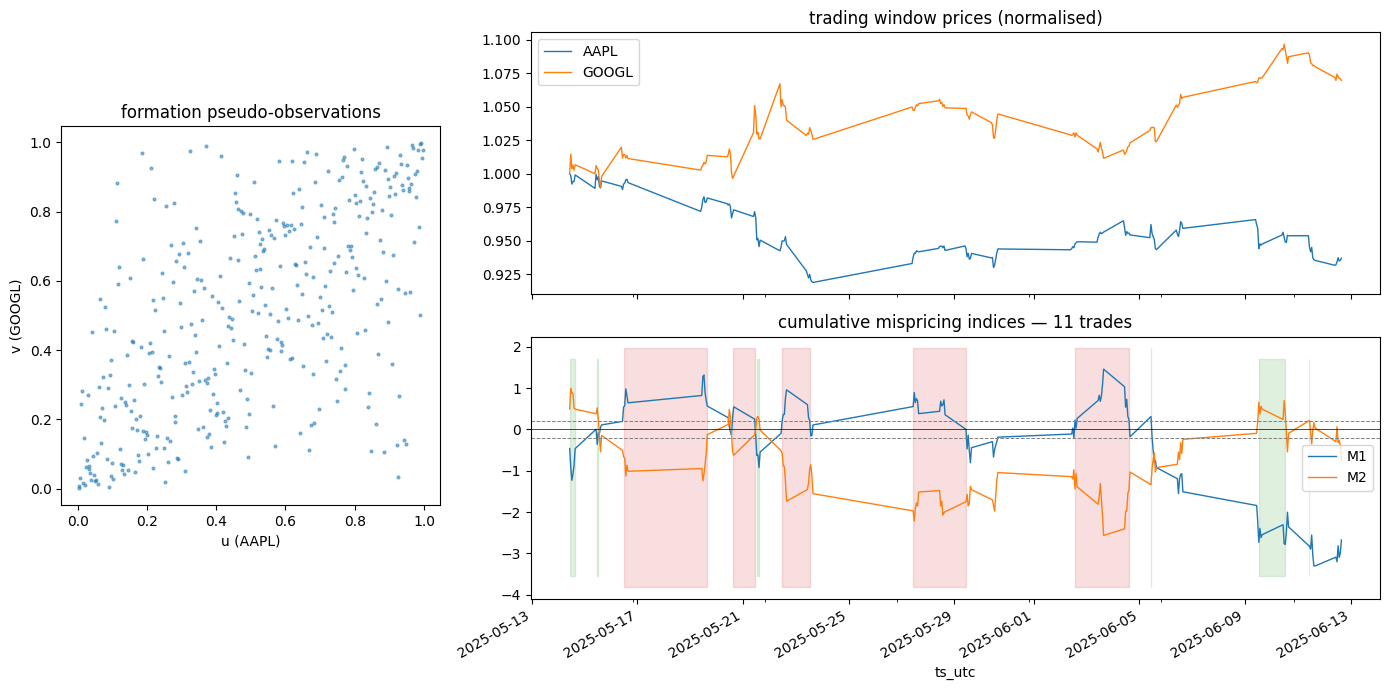

MC_RMS window 18: selected CtG, params {'Clayton': np.float64(1.121), 'Student-t': array([ 0.791, 13.301]), 'Gumbel': np.float64(2.973), 'weights': array([0.049, 0.889, 0.062])}


,k,loglik,aic,bic,lambda_L,lambda_U
copula,,,,,,
Gaussian,1,236.169,-470.338,-466.115,0.000,0.000
Student-t,2,238.992,-473.985,-465.540,0.275,0.275
Clayton,1,184.451,-366.902,-362.679,0.665,0.000
Frank,1,215.235,-428.469,-424.247,0.000,0.000
Gumbel,1,226.084,-450.167,-445.945,0.000,0.634
CFG,5,235.687,-461.374,-440.261,0.171,0.452
CtG,6,239.357,-466.713,-441.378,0.219,0.238


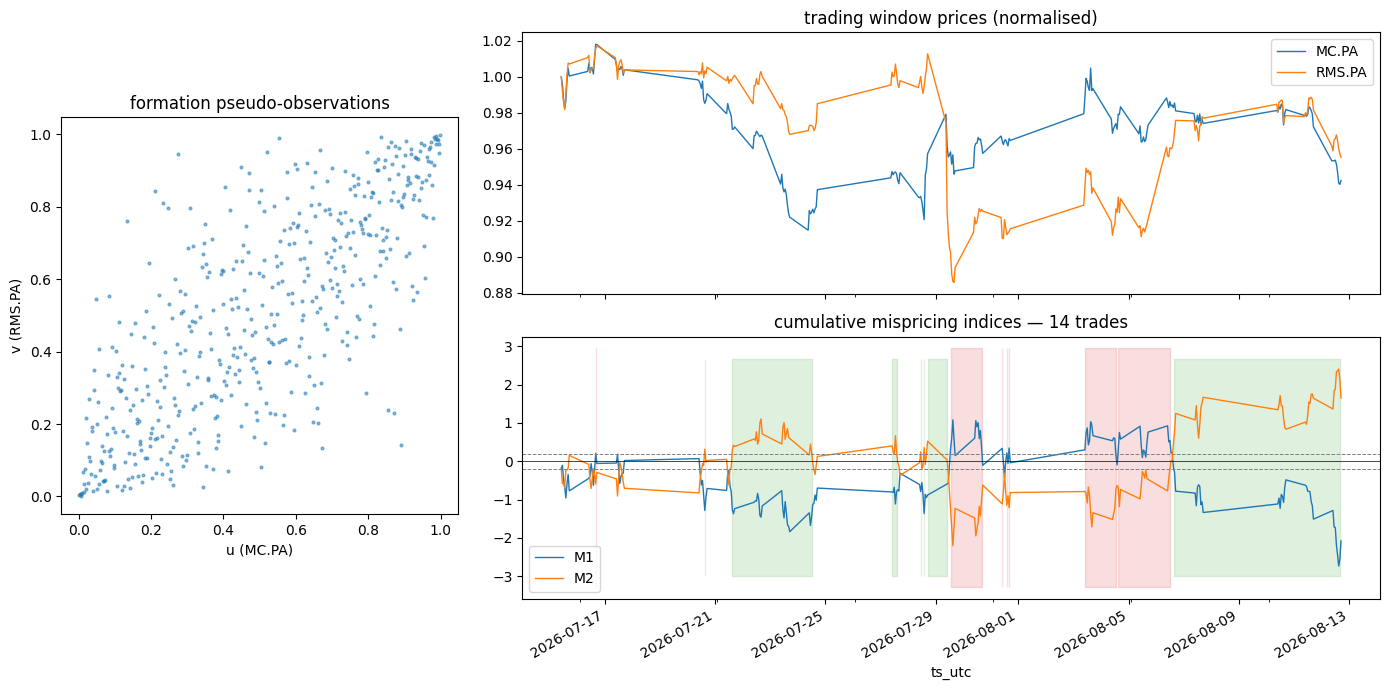

In [13]:
def plot_window(pair: str, i: int):
    tx, ty = PAIRS[pair]["tickers"]
    m, s = models[pair][i], signals[pair].query("window == @i")
    print(f"{pair} window {i}: selected {m['copula'].name}, params {m['copula'].theta}")
    display(m["table"].round(3))

    fig = plt.figure(figsize=(14, 7)); gs = fig.add_gridspec(2, 3)
    ax = fig.add_subplot(gs[:, 0])
    ax.scatter(*m["u_form"], s=4, alpha=0.5); ax.set_aspect("equal")
    ax.set(xlabel=f"u ({tx})", ylabel=f"v ({ty})", title="formation pseudo-observations")

    px = prices[pair].loc[s.index[0]:s.index[-1]]
    ax1 = fig.add_subplot(gs[0, 1:]); (px / px.iloc[0]).plot(ax=ax1, lw=1); ax1.set_title("trading window prices (normalised)")
    ax2 = fig.add_subplot(gs[1, 1:], sharex=ax1)
    s[["M1", "M2"]].plot(ax=ax2, lw=1)
    for y in (D_OPEN, -D_OPEN): ax2.axhline(y, ls="--", lw=0.7, c="grey")
    ax2.axhline(0, lw=0.5, c="k")
    for val, col in ((1, "tab:green"), (-1, "tab:red")):
        ax2.fill_between(s.index, *ax2.get_ylim(), where=s.pos.eq(val), color=col, alpha=0.15, step="post")
    ax2.set_title(f"cumulative mispricing indices — {int((s.pos.diff().fillna(s.pos).ne(0) & s.pos.ne(0)).sum())} trades")
    plt.tight_layout(); plt.show()

for p in PAIRS:
    plot_window(p, int(diags[p].n_trades.idxmax()))      # window with the most trades

### 11.3 Signal summary

In [14]:
def trade_list(s: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for w, g in s.groupby("window"):
        chg = g.pos.ne(g.pos.shift(fill_value=0))
        starts = g.index[chg & g.pos.ne(0)]
        ends = g.index[chg & g.pos.eq(0)]
        for a in starts:
            b = ends[ends > a][0]
            rows.append({"window": w, "entry": a, "exit": b, "side": int(g.pos.loc[a]),
                         "bars": g.index.get_loc(b) - g.index.get_loc(a)})
    return pd.DataFrame(rows)

trades = {p: trade_list(signals[p]) for p in PAIRS}
summary = pd.DataFrame({p: {"windows": len(diags[p]), "trades": len(t),
                            "trades / window": len(t) / len(diags[p]),
                            "long X / short Y": (t.side == 1).sum(), "short X / long Y": (t.side == -1).sum(),
                            "median holding (bars)": t.bars.median(),
                            "time in market": signals[p].pos.ne(0).mean()} for p, t in trades.items()})
display(summary.round(2))

for p in PAIRS:
    signals[p].to_parquet(DATA_DIR / f"{p}_signals_1h.parquet")

,AAPL_GOOGL,MC_RMS
windows,20.00,20.00
trades,96.00,113.00
trades / window,4.80,5.65
long X / short Y,48.00,50.00
short X / long Y,48.00,63.00
median holding (bars),5.50,5.00
time in market,0.54,0.78


## 12. Backtest 

We use the second paper on Pairs trading Strategy based on Mixed Copulas for the backtesting and PNL estimation

 Each trade is a \$1 long / \$1 short position. It is self-financing, but returns are computed on \$1 of capital. The legs are bought and held for the life of the trade, with no rebalancing, and marked to market on every bar:
$$\text{pnl}_t = s\left[\frac{X_t - X_{t-1}}{X_{\text{entry}}} - \frac{Y_t - Y_{t-1}}{Y_{\text{entry}}}\right],\qquad \sum_{t\in\text{trade}}\text{pnl}_t = s\left[\Big(\tfrac{X_{\text{exit}}}{X_{\text{entry}}}-1\Big) - \Big(\tfrac{Y_{\text{exit}}}{Y_{\text{entry}}}-1\Big)\right],$$
with $s=+1$ for long $X$/short $Y$.

A complete pairs trade is two round trips, so 4 leg transactions. Each leg pays `COST_BPS_LEG`, i.e. 20 bp per complete pair trade by default. Rad et al. use 9 bp commission + 20 bp market impact which is ≈58 bp. That is daily-data!

Returns .
- Committed capital (CC): P&L divided by the number of pairs allocated capital. 
- Employed capital (EC): P&L divided by the number of pairs that actually traded that month.

With constant \$1 notional, equity is $1 + \sum \text{pnl}$ (no compounding). Drawdowns are measured on that curve.

Timing. `pos[t]` is decided at the close of bar $t$. With `EXEC_LAG = 1`, it is executed at the close of bar $t+1$; Rad et al. trade at the same close, which is `EXEC_LAG = 0`. Positions are carried through the overnight bar, so the gap P&L is included.

The distance method runs on the same windows, prices are rescaled to \$1, a position opens at a 2σ spread divergence and closes at the zero crossing.

In [15]:
COST_BPS_LEG = 5.0      # one-way cost per leg (commission + half-spread + impact); 4 legs -> 20 bp per complete pair trade
EXEC_LAG     = 1        # bars between signal (close of t) and execution; 0 = trade at the signal bar's close

In [16]:
def backtest_positions(px: pd.DataFrame, target: pd.Series, cost_bps_leg=COST_BPS_LEG, lag=EXEC_LAG):
    """$1 long / $1 short marked-to-market P&L (Rad, Low & Faff 2016, sec. 4.4-4.5).

    px     : prices of (X, Y) on every bar, overnight bar included
    target : desired position on px.index (+1 long X/short Y, -1 short X/long Y, 0 flat), decided at bar close
    At entry we buy $1 of one leg and short $1 of the other (buy-and-hold within the trade, no rebalancing):
        pnl_t = s * [ (X_t - X_{t-1}) / X_entry  -  (Y_t - Y_{t-1}) / Y_entry ]
    Each leg traded costs cost_bps_leg, so a complete pair trade (open + close, 2 legs each) costs 4 x cost_bps_leg.
    """
    held = target.reindex(px.index).ffill().fillna(0).shift(lag).fillna(0).astype(int).to_numpy()
    X, Y = px.iloc[:, 0].to_numpy(), px.iloc[:, 1].to_numpy()
    c = cost_bps_leg * 1e-4
    n = len(px)
    pnl, cost = np.zeros(n), np.zeros(n)
    trades, s_prev, ex, ey, t_in = [], 0, np.nan, np.nan, None

    def close_trade(t):
        g = s_prev * ((X[t] / ex - 1) - (Y[t] / ey - 1))
        trades.append({"entry": px.index[t_in], "exit": px.index[t], "side": s_prev, "bars": t - t_in,
                       "gross": g, "net": g - 4 * c})

    for t in range(n):
        s = held[t]
        if t > 0 and s_prev != 0:
            pnl[t] = s_prev * ((X[t] - X[t - 1]) / ex - (Y[t] - Y[t - 1]) / ey)
        if s != s_prev:
            cost[t] = 2 * c * abs(s - s_prev)              # 2 legs per unit of position change
            if s_prev != 0:
                close_trade(t)
            if s != 0:
                ex, ey, t_in = X[t], Y[t], t
        s_prev = s
    if s_prev != 0:                                        # still open at the end of the sample: mark to market
        close_trade(n - 1)

    bars = pd.DataFrame({"held": held, "gross": pnl, "cost": cost, "net": pnl - cost}, index=px.index)
    return bars, pd.DataFrame(trades)

In [ ]:
def distance_signals(pair: str, k_sigma: float = 2.0) -> pd.Series:
    """Distance method on the same windows, all bars.
    Prices rescaled to $1 at the start of formation and of trading; open at |spread| > 2 sigma_formation,
    close when the spread crosses zero, force-close at the end of the trading window."""
    tx, ty = PAIRS[pair]["tickers"]
    px = prices[pair]; d = px.index.date
    out = []
    for _, w in rolling_windows(px.index).iterrows():
        f = px[(d >= w.form_start) & (d <= w.form_end)]
        t = px[(d >= w.trade_start) & (d <= w.trade_end)]
        nf, nt = f / f.iloc[0], t / t.iloc[0]
        sd = (nf[tx] - nf[ty]).std()
        spread = (nt[tx] - nt[ty]).to_numpy()
        pos, p = np.zeros(len(t), dtype=int), 0
        for i, s in enumerate(spread):
            if p == 0:
                p = -1 if s > k_sigma * sd else (+1 if s < -k_sigma * sd else 0)
            elif (p == -1 and s <= 0) or (p == +1 and s >= 0):
                p = 0
            pos[i] = p
        pos[-1] = 0
        out.append(pd.Series(pos, index=t.index))
    return pd.concat(out)

In [ ]:
bt = {}                       # bt[(strategy, pair)] = (bars, trades)
for p in PAIRS:
    tx, ty = PAIRS[p]["tickers"]
    px = prices[p][[tx, ty]]
    bt[("copula", p)] = backtest_positions(px, signals[p].pos)
    bt[("distance", p)] = backtest_positions(px, distance_signals(p))

for (strat, p), (bars, tr) in bt.items():
    print(f"{strat:8s} {p:11s} trades={len(tr):4d}  gross={bars.gross.sum():+.2%}  "
          f"costs={bars.cost.sum():.2%}  net={bars.net.sum():+.2%}  time in market={bars.held.ne(0).mean():.0%}")

copula   AAPL_GOOGL  trades=  96  gross=+30.80%  costs=19.20%  net=+11.60%  time in market=46%
distance AAPL_GOOGL  trades=   8  gross=+1.57%  costs=1.60%  net=-0.03%  time in market=17%
copula   MC_RMS      trades= 113  gross=-34.15%  costs=22.60%  net=-56.75%  time in market=65%
distance MC_RMS      trades=   8  gross=+8.49%  costs=1.60%  net=+6.89%  time in market=15%


## 13. Performance

Trade statistics are computed on per-trade returns:
- hit rate $=P(r>0)$;
- $E[r\mid\text{hit}]$ and $E[r\mid\text{miss}]$;
- expectancy $=\text{hit}\cdot E[r\mid\text{hit}] + (1-\text{hit})\cdot E[r\mid\text{miss}]$;
- payoff ratio $=E[r\mid\text{hit}]/|E[r\mid\text{miss}]|$.

- **Max drawdown** is measured on $1+\sum\text{pnl}$, both on daily closes and intrabar (hourly) for single pairs. Its length is in trading days.


In [22]:
def daily_pnl(bars: pd.DataFrame, col: str) -> pd.Series:
    """Daily P&L on $1 committed capital, indexed by local trading date."""
    s = bars[col].groupby(bars.index.date).sum()
    s.index = pd.to_datetime(s.index)
    return s


def monthly_ec(daily: pd.Series, bars_list: list) -> pd.Series:
    """Rad eq. 14: monthly P&L divided by the number of pairs that actually traded that month (NaN if none)."""
    m = daily.resample("ME").sum()
    n_traded = sum(b.held.ne(0).groupby(b.index.tz_localize(None).to_period("M")).max()
                   .reindex(m.index.to_period("M"), fill_value=False).to_numpy().astype(int) for b in bars_list)
    return (m * len(bars_list) / n_traded).where(n_traded > 0)


def portfolio(strat: str, col: str) -> pd.Series:
    """Equal committed capital across pairs (Rad eq. 15 with NP = number of pairs): daily P&L."""
    return pd.concat({p: daily_pnl(bt[(strat, p)][0], col) for p in PAIRS}, axis=1).fillna(0).mean(axis=1)


def max_drawdown(pnl: pd.Series) -> tuple[float, int]:
    """MDD of the equity 1 + cumulative P&L (constant $1 notional, no compounding), and its length in periods."""
    eq = 1 + pnl.cumsum()
    dd = eq / eq.cummax() - 1
    under = dd.lt(0).astype(int)
    longest = under.groupby((under == 0).cumsum()).sum().max()
    return dd.min(), int(longest)


def performance(daily: pd.Series, trades: pd.DataFrame, col: str, m_ec: pd.Series = None,
                bars: pd.DataFrame = None) -> dict:
    r = trades[col] if len(trades) else pd.Series(dtype=float)
    win, loss = r[r > 0], r[r <= 0]
    m_cc = daily.resample("ME").sum()                                    # Rad eq. 15 (committed capital)
    mdd, mdd_len = max_drawdown(daily)
    ann = daily.mean() * 252
    down = np.sqrt((np.minimum(daily, 0) ** 2).mean())
    q = m_cc.quantile(0.05)
    out = {
        "trades": len(r),
        "hit rate": (r > 0).mean() if len(r) else np.nan,
        "E[r | hit]": win.mean(),
        "E[r | miss]": loss.mean(),
        "expectancy / trade": r.mean(),
        "payoff ratio": win.mean() / abs(loss.mean()) if len(loss) and len(win) else np.nan,
        "median holding (bars)": trades.bars.median() if len(trades) else np.nan,
        "total return": daily.sum(),
        "ann. return": ann,
        "ann. vol": daily.std() * np.sqrt(252),
        "Sharpe (daily, ann.)": ann / (daily.std() * np.sqrt(252)),
        "Sortino (ann.)": ann / (down * np.sqrt(252)),
        "max drawdown": mdd,
    }
    if bars is not None:
        out["intraday max drawdown"] = max_drawdown(bars[col])[0]
    return out


def perf_table(col: str) -> pd.DataFrame:
    res = {}
    for strat in ("copula", "distance"):
        for p in PAIRS:
            bars, tr = bt[(strat, p)]
            d = daily_pnl(bars, col)
            res[(strat, p)] = performance(d, tr, col, monthly_ec(d, [bars]), bars)
        d = portfolio(strat, col)
        res[(strat, "portfolio")] = performance(d, pd.concat([bt[(strat, p)][1] for p in PAIRS]), col,
                                                monthly_ec(d, [bt[(strat, p)][0] for p in PAIRS]))
    return pd.DataFrame(res)

pct_rows = ["hit rate", "E[r | hit]", "E[r | miss]", "expectancy / trade", "total return", "ann. return", "ann. vol",
            "max drawdown", "intraday max drawdown",]

def show(tab: pd.DataFrame):
    fmt = tab.astype(object).copy()
    for r in tab.index:
        fmt.loc[r] = ["–" if pd.isna(v) else f"{v:.2%}" if r in pct_rows else f"{v:.2f}" for v in tab.loc[r]]
    display(fmt)

for col in ("net", "gross"):
    print(f"\n{'After' if col == 'net' else 'Before'} transaction costs ({4 * COST_BPS_LEG:.0f} bp per complete pair trade)")
    show(perf_table(col))


After transaction costs (20 bp per complete pair trade)


copula                      distance                   
                      AAPL_GOOGL   MC_RMS portfolio AAPL_GOOGL   MC_RMS portfolio
trades                     96.00   113.00    209.00       8.00     8.00     16.00
hit rate                  50.00%   43.36%    46.41%     62.50%   50.00%    56.25%
E[r | hit]                 2.04%    1.07%     1.55%      3.86%    4.89%     4.32%
E[r | miss]               -1.80%   -1.71%    -1.75%     -6.45%   -3.17%    -4.58%
expectancy / trade         0.12%   -0.50%    -0.22%     -0.00%    0.86%     0.43%
payoff ratio                1.13     0.63      0.89       0.60     1.54      0.94
median holding (bars)       6.50     6.00      6.00      72.00    72.50     72.50
total return              11.60%  -56.75%   -22.58%     -0.03%    6.89%     3.43%
ann. return                5.92%  -28.49%   -11.11%     -0.02%    3.46%     1.69%
ann. vol                  23.68%   20.48%    15.75%     13.19%   11.39%     8.80%
Sharpe (daily, ann.)        0.25    -1.39     -0.71      -0.00     0.30      0.19
Sortino (ann.)              0.37    -1.72     -0.95      -0.00     0.59      0.30
max drawdown             -17.02%  -73.09%   -36.51%    -16.79%  -15.31%   -12.80%
intraday max drawdown    -18.31%  -73.33%         –    -18.16%  -15.94%         –


Before transaction costs (20 bp per complete pair trade)


copula                      distance                   
                      AAPL_GOOGL   MC_RMS portfolio AAPL_GOOGL   MC_RMS portfolio
trades                     96.00   113.00    209.00       8.00     8.00     16.00
hit rate                  58.33%   50.44%    54.07%     62.50%   50.00%    56.25%
E[r | hit]                 1.93%    1.11%     1.51%      4.06%    5.09%     4.52%
E[r | miss]               -1.93%   -1.74%    -1.82%     -6.25%   -2.97%    -4.38%
expectancy / trade         0.32%   -0.30%    -0.02%      0.20%    1.06%     0.63%
payoff ratio                1.00     0.64      0.83       0.65     1.71      1.03
median holding (bars)       6.50     6.00      6.00      72.00    72.50     72.50
total return              30.80%  -34.15%    -1.68%      1.57%    8.49%     5.03%
ann. return               15.71%  -17.14%    -0.82%      0.80%    4.26%     2.47%
ann. vol                  23.70%   20.47%    15.82%     13.19%   11.47%     8.82%
Sharpe (daily, ann.)        0.66    -0.84     -0.05       0.06     0.37      0.28
Sortino (ann.)              1.01    -1.06     -0.07       0.08     0.73      0.44
max drawdown             -13.06%  -57.52%   -22.00%    -16.38%  -14.49%   -11.93%
intraday max drawdown    -13.68%  -57.83%         –    -17.76%  -15.12%         –

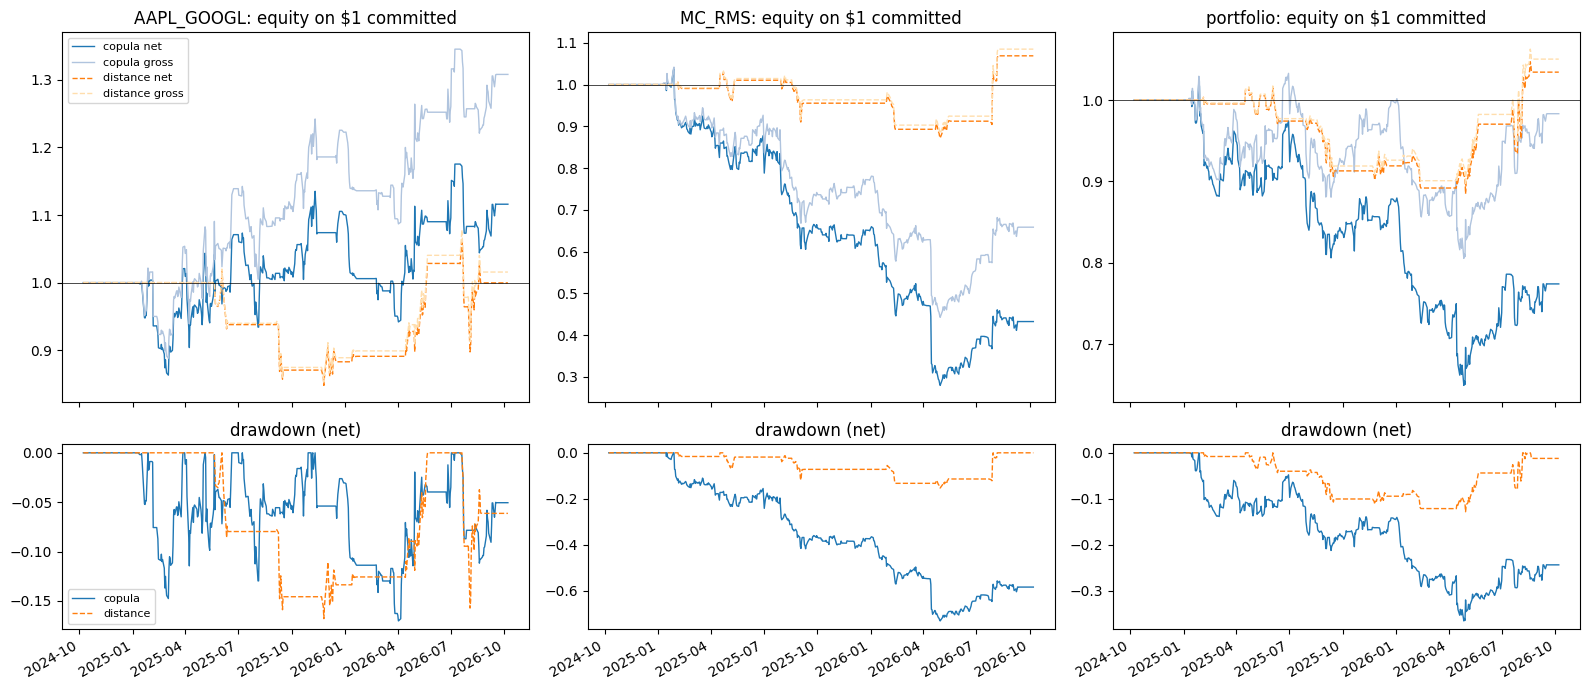

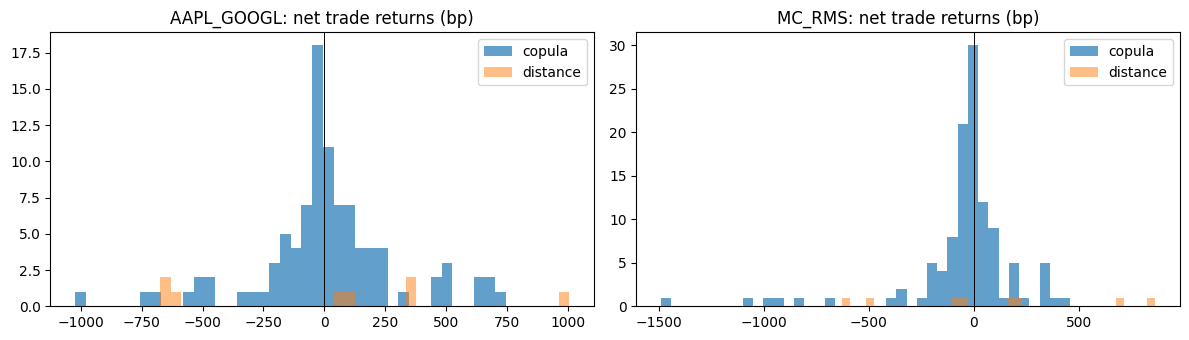

In [20]:
COLORS = {("copula", "net"): "tab:blue", ("copula", "gross"): "lightsteelblue",
          ("distance", "net"): "tab:orange", ("distance", "gross"): "navajowhite"}

fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex="col", gridspec_kw={"height_ratios": [2, 1]})
for j, p in enumerate(list(PAIRS) + ["portfolio"]):
    for strat, ls in (("copula", "-"), ("distance", "--")):
        for col in ("net", "gross"):
            d = portfolio(strat, col) if p == "portfolio" else daily_pnl(bt[(strat, p)][0], col)
            eq = 1 + d.cumsum()
            axes[0, j].plot(eq, ls=ls, c=COLORS[(strat, col)], lw=1, label=f"{strat} {col}")
            if col == "net":
                axes[1, j].plot(eq / eq.cummax() - 1, ls=ls, c=COLORS[(strat, col)], lw=1, label=strat)
    axes[0, j].set_title(f"{p}: equity on $1 committed"); axes[1, j].set_title("drawdown (net)")
    axes[0, j].axhline(1, lw=0.5, c="k")
axes[0, 0].legend(fontsize=8); axes[1, 0].legend(fontsize=8)
fig.autofmt_xdate()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, p in zip(axes, PAIRS):
    tr = bt[("copula", p)][1]
    ax.hist(tr.net * 1e4, bins=40, alpha=0.7, label="copula")
    ax.hist(bt[("distance", p)][1].net * 1e4, bins=40, alpha=0.5, label="distance")
    ax.axvline(0, c="k", lw=0.7); ax.set_title(f"{p}: net trade returns (bp)"); ax.legend()
plt.tight_layout(); plt.show()